In [ ]:
from scripts.general_nn import generalNN
from scripts import plots
import importlib


from dataclasses import replace

from scripts.general_nn import generalNN
from scripts.settings import Settings
from scripts import plots


# Use a small training budget for this first experiment.
settings = Settings(
    warmup_updates=100,
    continuation_updates=100,
    number_of_replicates=1,

    # Check validation performance every 25 training updates.
    validation_interval=25,

    # Set the sizes of the calibration, validation, and test datasets.
    normalization_size=2048,
    validation_size=2048,
    test_size=8192,

    # Used only if we choose to train from a fixed dataset.
    static_training_size=8192,
)


In [2]:

# dynamic_data:
# True: generate fresh training batches during each iteration.
# False: sample batches from one fixed training dataset.


# Create a new paper-style model that trades using stock and the variance information.
paper = generalNN(
    method="paper",
    settings=settings,
    dynamic_data=False,
    name="Paper network: stock + variance",
)

# Copy the settings and disable trading using variance.
control_settings = replace(settings, trade_variance=False)

# Create a new paper-style model restricted to stock trading.
control = generalNN(
    method="paper",
    settings=control_settings,
    dynamic_data=False,
)

# Create a new model using our smaller network design.
ours = generalNN(
    method="ours",
    settings=settings,
    dynamic_data=True,
    name="Our network: stock only",
)


# Keep our settings, but use the same instruments as the full reference.
settings_with_variance = replace(
    ours.settings,
    instruments=paper.settings.instruments,
    trade_variance=True,
)

ours_variance = generalNN(
    method="ours",
    settings=settings_with_variance,
    dynamic_data=ours.dynamic_data,
    name="Our network: stock + variance",
)

In [3]:
# Train and evaluate each newly created model.
for model in (paper, control, ours, ours_variance):

    print(f"\nTraining: {model.name}")

    # Prepare the training data and fit the hedging policies.
    model.train(verbose=True)

    # Measure the trained policies on separate test paths.
    model.evaluate()


Training: Paper network: stock + variance
paper_full_0_warmup: update 0, validation risk 6.37034
paper_full_0_warmup: update 100, validation risk 2.62717
paper_full_0_CVaR: update 0, validation risk 2.61986
paper_full_0_CVaR: update 100, validation risk 2.57061
paper_full_0_Entropic: update 0, validation risk 11.57463
paper_full_0_Entropic: update 100, validation risk 2.60560

Training: Paper style: stock only
paper_stock_0_warmup: update 0, validation risk 5.24981
paper_stock_0_warmup: update 100, validation risk 2.90243
paper_stock_0_CVaR: update 0, validation risk 2.90334
paper_stock_0_CVaR: update 100, validation risk 2.96091
paper_stock_0_Entropic: update 0, validation risk 13.20674
paper_stock_0_Entropic: update 100, validation risk 4.65567

Training: Our network: stock only
ours_0_warmup: update 0, validation risk 4.15072
ours_0_warmup: update 100, validation risk 2.79663
ours_0_CVaR: update 0, validation risk 2.79663
ours_0_CVaR: update 100, validation risk 2.76602
ours_0_Entr

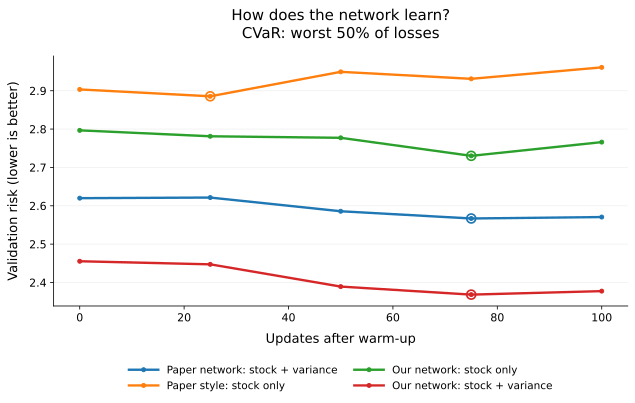

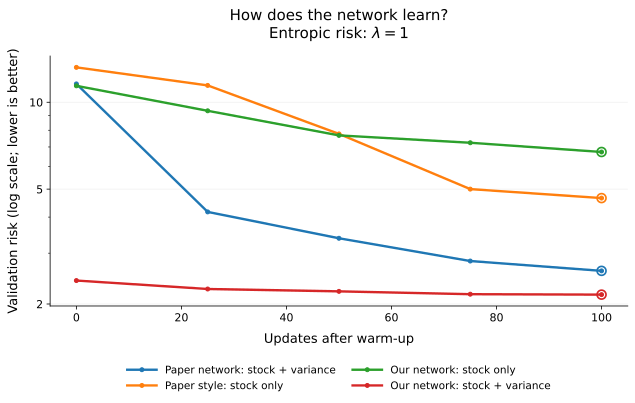

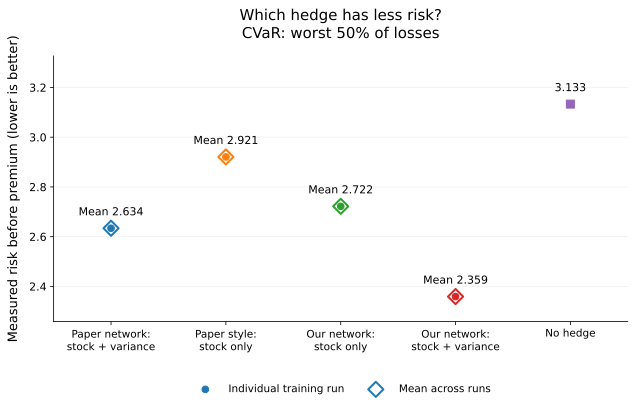

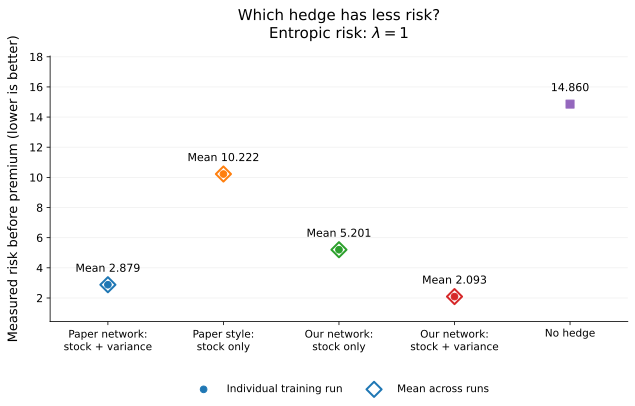

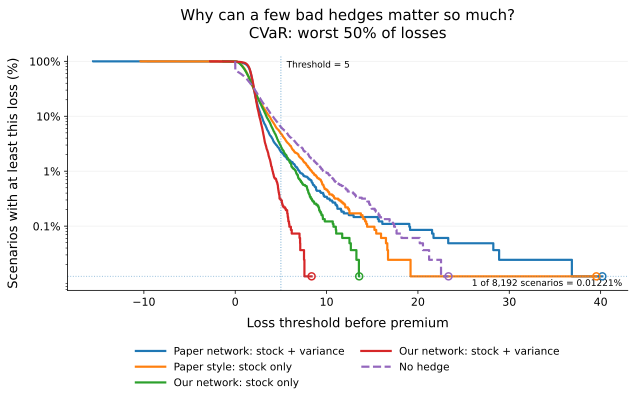

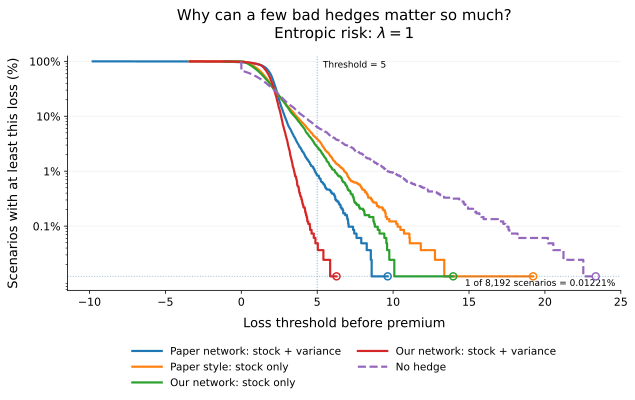

In [4]:
experiments = [paper, control, ours, ours_variance]

plots.plot_learning(experiments)
plots.plot_risk(experiments)
plots.plot_loss_tails(experiments)

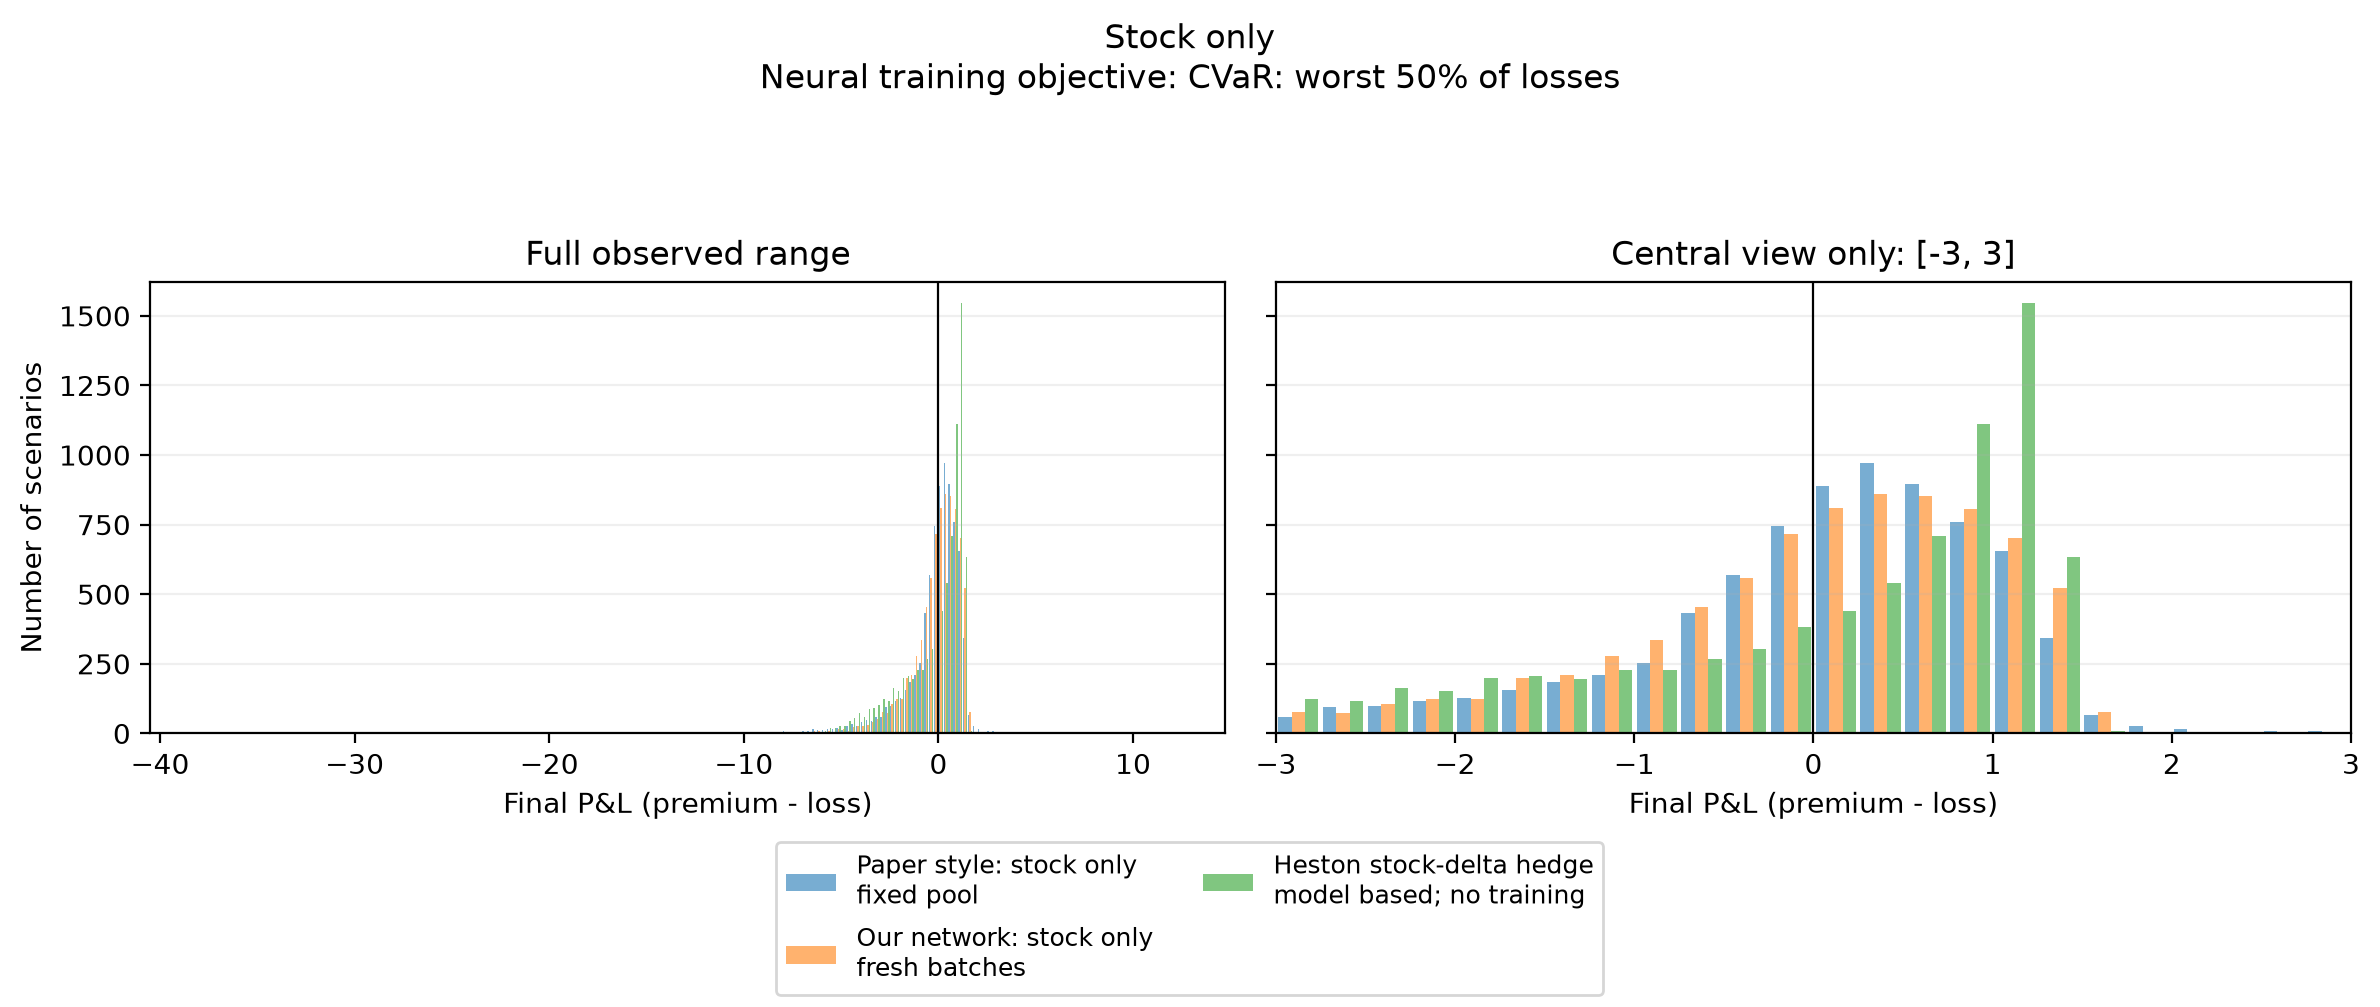


Stock only: CVaR of terminal loss
Paper style: stock only: 2.920766
Our network: stock only: 2.721998
Heston benchmark: 3.050971


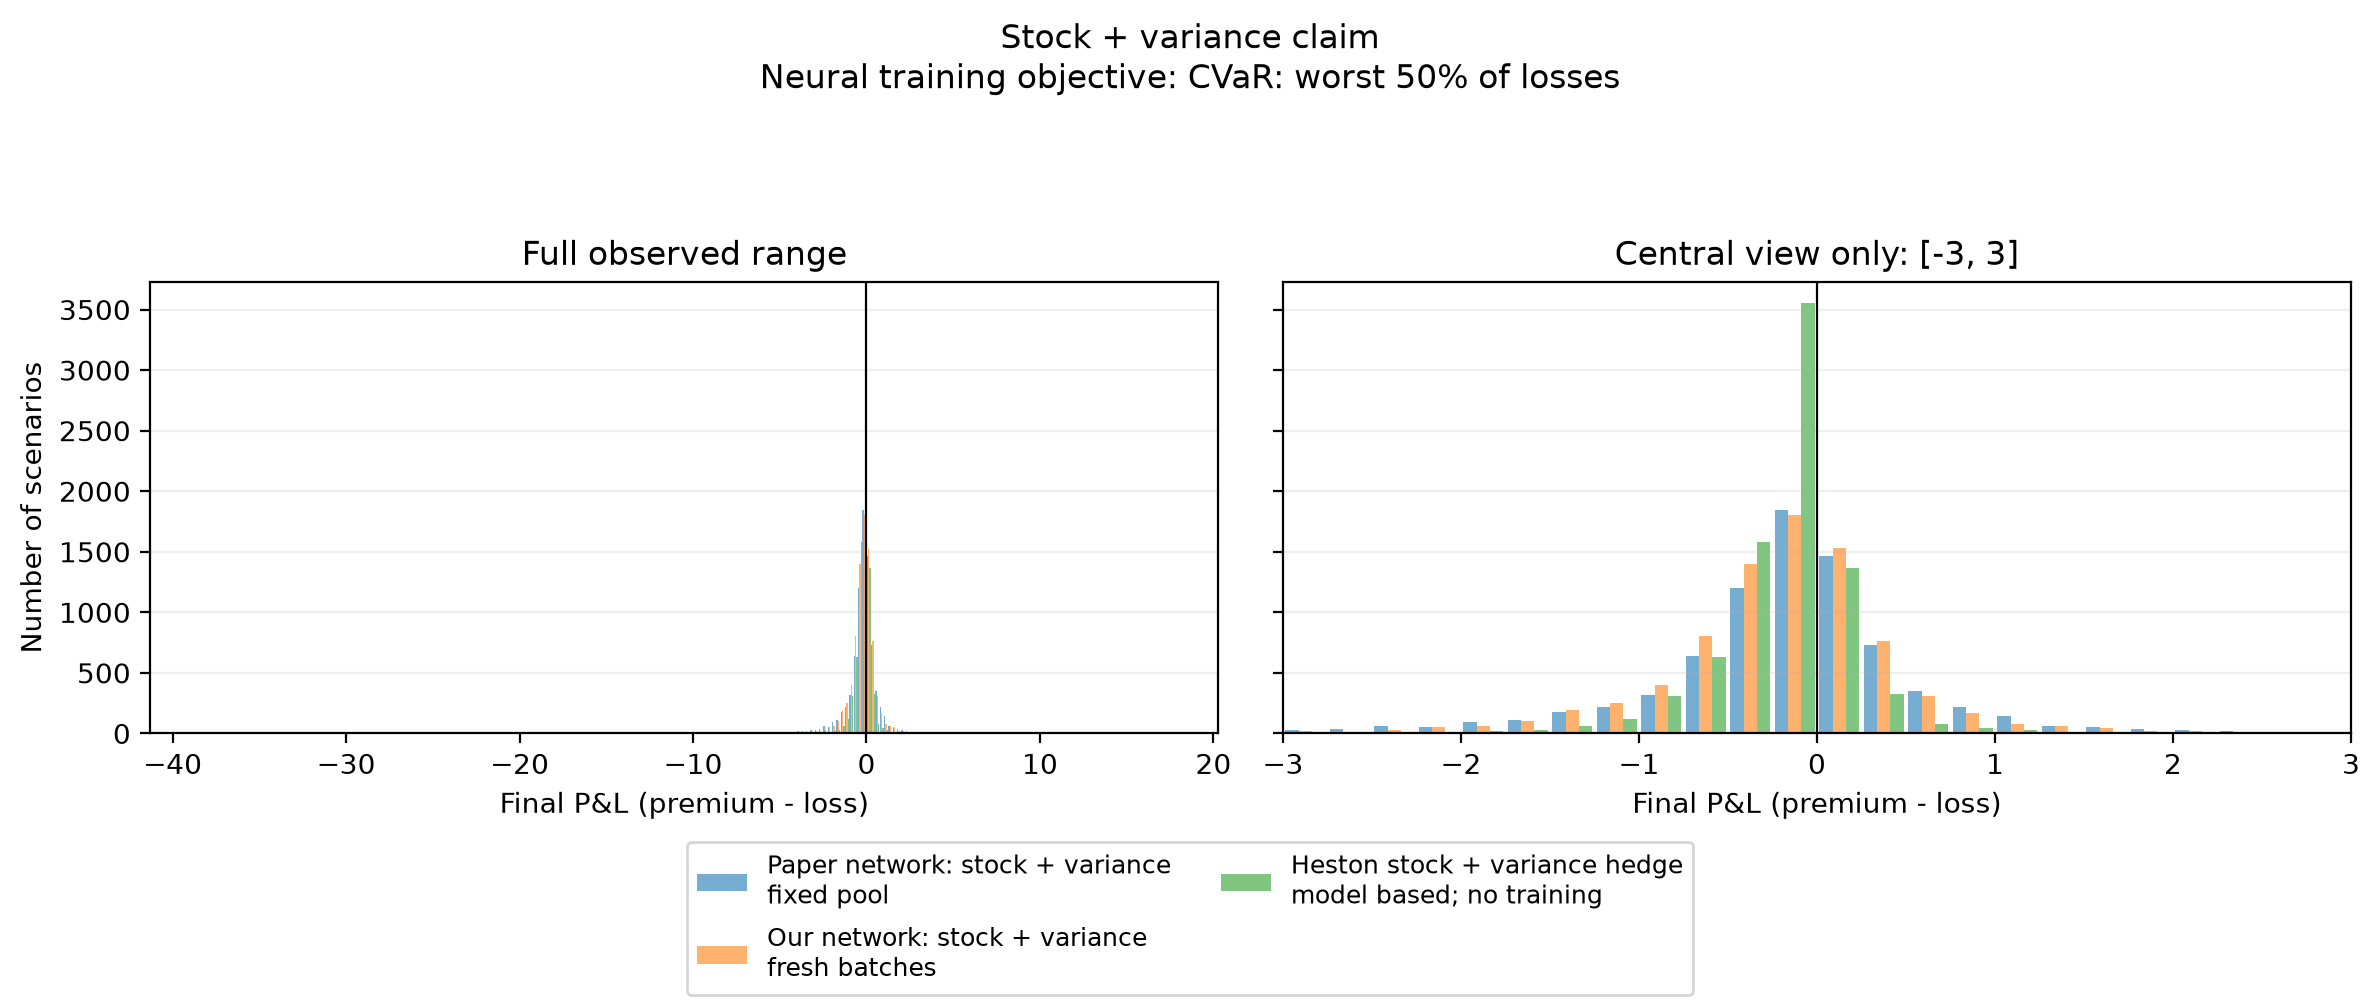


Stock + variance claim: CVaR of terminal loss
Paper network: stock + variance: 2.633836
Our network: stock + variance: 2.359043
Heston benchmark: 2.140603


In [7]:
from scripts.general_nn import call_price
from scripts import plots

# Use the same premium for every strategy.
premium = call_price(ours.settings)

# Compare each network against a Heston hedge with the same instruments.
comparisons = [
    (control, ours, "Stock only"),
    (paper, ours_variance, "Stock + variance claim"),
]

for reference, other, title in comparisons:
    # Compute and store the Heston benchmark on the existing test paths.
    reference.evaluate(include_heston=True)

    # Explicitly include its P&L distribution in the figure.
    plots.plot_pnl_comparison(
        [reference, other],
        premium=premium,
        objective="CVaR",
        title=title,
        include_heston=True,
    )

    # Print numerical comparisons as well as showing the histogram.
    print(f"\n{title}: CVaR of terminal loss")
    for model in (reference, other):
        score = model.get_run("CVaR", replicate=0)["metrics"]["cvar"]
        print(f"{model.name}: {score:.6f}")

    score = reference.benchmarks["heston"]["cvar"]
    print(f"Heston benchmark: {score:.6f}")

In [8]:
#import importlib
# from scripts import plots
# from scripts.general_nn import call_price

# importlib.reload(plots)

# # Use exactly the same premium for both comparisons.
# premium = call_price(ours.settings)

# plots.plot_pnl_comparison(
#     [control, ours],
#     premium=premium,
#     title="Stock only",
# )

# plots.plot_pnl_comparison(
#     [paper, ours_variance],
#     premium=premium,
#     title="Stock + variance claim",
# )

# import numpy as np

# for model in [control, ours, paper, ours_variance]:
#     losses = model.losses("CVaR", replicate=0)
#     assert model.settings.alpha == 0.5 and len(losses) % 2 == 0

#     measured = np.sort(losses)[len(losses) // 2:].mean()
#     reported = model.get_run("CVaR", replicate=0)["metrics"]["cvar"]

#     assert np.isclose(measured, reported, rtol=1e-10, atol=1e-10)
#     print(f"{model.name}: test CVaR = {measured:.4f}")